# Experiment 1: the joint $N,\lambda$ limit on a fixed bandwidth interval

This notebook isolates the spectral asymptotics from the separate sample-size limit. It fixes one sample from $N(0,1)$ and the bandwidth interval $[0.05,1]$, then varies only the number $N$ of bandwidth candidates and the similarity scale $\lambda_N$.

$$D_{ij}=\frac12\int (\widehat f_{h_i}-\widehat f_{h_j})^2,\qquad
S_{ij}=e^{-\lambda_ND_{ij}},\qquad
h_{\mathrm{spec},N}=h_{\arg\max_i v_i^{(N)}},$$

where $v^{(N)}$ is the sum-normalized Perron vector of $S$. This is deliberately **not** an AMISE experiment and $n$ never changes.

The $\psi_2$ parametrization is $\psi_2(h)=\log h$, so the bandwidth candidates are geometrically spaced. Every grid has the same endpoints; increasing $N$ only refines the mesh. The admissible sequences satisfy

$$\lambda_N\to\infty,\qquad \lambda_N/N^2\to0,$$

while the remaining sequences deliberately violate one of these conditions.

In [24]:
from __future__ import annotations

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import eigh as symmetric_eigh
from scipy.optimize import minimize_scalar

# Complete supported project API, plus the deliberately separate
# optional Fourier API used for the large matrices.
from kde_tools import *
from kde_tools import __all__ as KDE_PUBLIC_API
from kde_tools.fourier import *
from kde_tools.fourier import __all__ as KDE_FOURIER_API

def largest_symmetric_perron_vector(
    matrix: np.ndarray,
) -> np.ndarray:
    """Return only the leading eigenvector of a symmetric matrix."""
    matrix = np.asarray(matrix, dtype=float)
    number_of_scales = matrix.shape[0]
    _, eigenvectors = symmetric_eigh(
        matrix,
        subset_by_index=[
            number_of_scales - 1,
            number_of_scales - 1,
        ],
        check_finite=False,
        overwrite_a=True,
        driver="evr",
    )
    vector = eigenvectors[:, 0]
    if vector.sum() < 0.0:
        vector = -vector
    return vector / vector.sum()

SEED = 20260902
N_DATA = 200
H_MIN, H_MAX = 0.05, 1.0
BETA = 2.0
N_VALUES = np.arange(100, 2001, 100)
FFT_HALF_WIDTH = 10.0
FFT_SPATIAL_POINTS = 4096

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=6, suppress=True)
print(
    f"Imported {len(KDE_PUBLIC_API)} public KDE helpers and "
    f"{len(KDE_FOURIER_API)} optional Fourier helpers."
)

Imported 31 public KDE helpers and 4 optional Fourier helpers.


In [25]:
rng = np.random.default_rng(SEED)
samples = rng.normal(loc=0.0, scale=1.0, size=N_DATA)

endpoint_check = pd.DataFrame({
    "N": N_VALUES,
    "first h": [
        bandwidth_grid_linear_in_psi_beta(
            H_MIN, H_MAX, BETA, int(N)
        )[0]
        for N in N_VALUES
    ],
    "last h": [
        bandwidth_grid_linear_in_psi_beta(
            H_MIN, H_MAX, BETA, int(N)
        )[-1]
        for N in N_VALUES
    ],
    "Delta log(h)": [
        np.log(H_MAX / H_MIN) / (N - 1) for N in N_VALUES
    ],
})

print(
    f"Fixed sample: n={N_DATA}, seed={SEED}, "
    f"mean={samples.mean():.4f}, sd={samples.std(ddof=1):.4f}"
)
display(endpoint_check)

Fixed sample: n=200, seed=20260902, mean=-0.0844, sd=0.9469


,N,first h,last h,Delta log(h)
0,100,0.05,1.0,0.030260
1,200,0.05,1.0,0.015054
2,300,0.05,1.0,0.010019
3,400,0.05,1.0,0.007508
4,500,0.05,1.0,0.006003
5,600,0.05,1.0,0.005001
6,700,0.05,1.0,0.004286
7,800,0.05,1.0,0.003749
8,900,0.05,1.0,0.003332
9,1000,0.05,1.0,0.002999


## Continuous large-$N$, large-$\lambda$ prediction

Write $\psi=\log h$. Locally, beta-2 divergence has the quadratic expansion

$$D_2(\widehat f_h,\widehat f_{he^\delta})
=a(h)\delta^2+o(\delta^2),\qquad
a(h)=\frac12\left\|\partial_\psi\widehat f_h\right\|_2^2.$$

The localized continuous kernel has row width proportional to $a(h)^{-1/2}$, so its Perron mass concentrates at

$$h_\infty=\operatorname*{arg\,min}_{h\in[0.05,1]}a(h).$$

For Gaussian KDEs, this coefficient can be evaluated without numerical differentiation. If $d_{rs}=(X_r-X_s)^2$, $q=2h^2$, and $g_q(d)=(2\pi q)^{-1/2}e^{-d/(2q)}$, then

$$a(h)=2h^4\frac1{n^2}\sum_{r,s}g_q(d_{rs})
\left(\frac{3}{4q^2}-\frac{3d_{rs}}{2q^3}
+\frac{d_{rs}^2}{4q^4}\right).$$

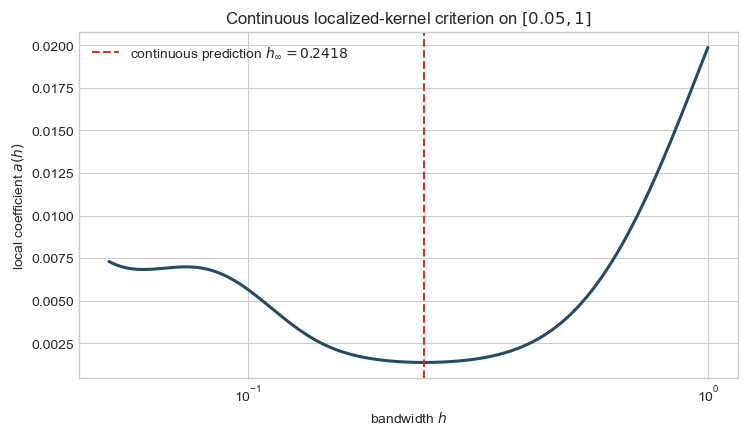

Continuous-limit prediction: h_infinity = 0.24175622


In [3]:
squared_sample_differences = (
    samples[:, None] - samples[None, :]
) ** 2

def local_beta2_log_metric(
    bandwidth: float,
    squared_differences: np.ndarray,
) -> float:
    """Exact coefficient of (Delta log h)^2 for this KDE family."""
    h = float(bandwidth)
    q = 2.0 * h**2
    d = np.asarray(squared_differences, dtype=float)
    overlap = np.exp(-d / (2.0 * q)) / np.sqrt(2.0 * np.pi * q)
    second_q_factor = (
        3.0 / (4.0 * q**2)
        - 3.0 * d / (2.0 * q**3)
        + d**2 / (4.0 * q**4)
    )
    return float(
        2.0 * h**4 * np.mean(overlap * second_q_factor)
    )

continuous_minimum = minimize_scalar(
    lambda h: local_beta2_log_metric(
        h, squared_sample_differences
    ),
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)
if not continuous_minimum.success:
    raise RuntimeError(continuous_minimum.message)

h_infinity = float(continuous_minimum.x)
metric_grid = np.geomspace(H_MIN, H_MAX, 600)
metric_values = np.array([
    local_beta2_log_metric(h, squared_sample_differences)
    for h in metric_grid
])

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(
    metric_grid, metric_values,
    color="#244c66", linewidth=2.2
)
ax.axvline(
    h_infinity, color="#c23b22", linestyle="--",
    label=rf"continuous prediction $h_\infty={h_infinity:.4f}$",
)
ax.set(
    xscale="log",
    xlabel=r"bandwidth $h$",
    ylabel=r"local coefficient $a(h)$",
    title=r"Continuous localized-kernel criterion on $[0.05,1]$",
)
ax.legend()
plt.show()
print(f"Continuous-limit prediction: h_infinity = {h_infinity:.8f}")

## Numerical method and validation

The project already contains an exact analytic beta-2 calculation. Its cost grows like $N^2n^2$, so the full sweep uses the existing Fourier reconstruction and one matrix product per $N$. The next cell checks that approximation against the exact helper on the smallest grid.

In [4]:
validation_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX, beta=BETA, grid_size=25
)
validation_exact = beta2_divergence_matrix(
    samples, validation_grid
)
validation_fft = beta2_divergence_matrix_fft(
    samples, validation_grid,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
)
validation_abs_error = np.max(
    np.abs(validation_fft - validation_exact)
)
validation_rel_error = (
    validation_abs_error / np.max(validation_exact)
)

print(f"maximum absolute D2 error: {validation_abs_error:.3e}")
print(f"error relative to max(D2): {validation_rel_error:.3e}")
if validation_rel_error > 2e-5:
    warnings.warn(
        "Increase FFT_HALF_WIDTH or FFT_SPATIAL_POINTS."
    )

maximum absolute D2 error: 3.331e-16
error relative to max(D2): 1.675e-14


In [5]:
LAMBDA_RULES = {
    r"$N^{1/2}$ (admissible)": lambda N: N**0.5,
    r"$N$ (admissible)": lambda N: float(N),
    r"$N^{3/2}$ (admissible)": lambda N: N**1.5,
    r"$1$ (not localized)": lambda N: 1.0,
    r"$N^2$ (mesh-scale)": lambda N: float(N**2),
    r"$N^3$ (collapse)": lambda N: float(N**3),
}
REGIME_ORDER = list(LAMBDA_RULES)
REGIME_COLORS = dict(zip(
    REGIME_ORDER,
    ["#0072B2", "#009E73", "#CC79A7",
     "#E69F00", "#7A7A7A", "#D55E00"],
))

rows = []
largest_grid_vectors = {}
start_time = time.perf_counter()

for N in N_VALUES:
    N = int(N)
    h_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN, h_max=H_MAX,
        beta=BETA, grid_size=N,
    )
    divergence = beta2_divergence_matrix_fft(
        samples, h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )
    reference_index = nearest_bandwidth_grid_index(
        h_infinity, h_grid
    )
    neighbor_left = min(reference_index, N - 2)
    neighbor_D = divergence[
        neighbor_left, neighbor_left + 1
    ]
    endpoint_D = divergence[0, -1]

    for regime, lambda_rule in LAMBDA_RULES.items():
        lambda_value = float(lambda_rule(N))
        similarity = np.exp(-lambda_value * divergence)
        np.fill_diagonal(similarity, 1.0)
        vector = largest_symmetric_perron_vector(similarity)
        selected_index = int(np.argmax(vector))
        selected_h = float(h_grid[selected_index])

        rows.append({
            "N": N,
            "regime": regime,
            "lambda": lambda_value,
            "lambda_over_N2": lambda_value / N**2,
            "selected_index": selected_index,
            "selected_h": selected_h,
            "absolute_error": abs(selected_h - h_infinity),
            "global_exponent": lambda_value * endpoint_D,
            "neighbor_exponent": lambda_value * neighbor_D,
            "neighbor_similarity": np.exp(
                -lambda_value * neighbor_D
            ),
        })
        if N == int(N_VALUES[-1]):
            largest_grid_vectors[regime] = (
                h_grid.copy(), vector.copy()
            )

results = pd.DataFrame(rows)
results["regime"] = pd.Categorical(
    results["regime"],
    categories=REGIME_ORDER,
    ordered=True,
)
results = results.sort_values(
    ["regime", "N"]
).reset_index(drop=True)

elapsed = time.perf_counter() - start_time
print(
    f"Completed {len(results)} selector runs "
    f"in {elapsed:.2f} seconds."
)
display(results.pivot(
    index="N", columns="regime", values="selected_h"
).round(6))

Completed 120 selector runs in 53.64 seconds.


regime,$N^{1/2}$ (admissible),$N$ (admissible),$N^{3/2}$ (admissible),$1$ (not localized),$N^2$ (mesh-scale),$N^3$ (collapse)
N,,,,,,
100,0.264098,0.233990,0.241179,0.264098,0.241179,0.241179
200,0.257985,0.232183,0.242909,0.261898,0.242909,0.242909
300,0.255992,0.233919,0.241057,0.263804,0.241057,0.241057
400,0.255004,0.236560,0.241948,0.262779,0.241948,0.241948
500,0.254414,0.236730,0.242484,0.262167,0.242484,0.242484
600,0.252755,0.238032,0.242842,0.261760,0.241630,0.241630
700,0.251576,0.238965,0.242058,0.262593,0.242058,0.242058
800,0.251639,0.239667,0.242378,0.262234,0.242378,0.241471
900,0.250850,0.240215,0.242628,0.261955,0.241821,0.241821


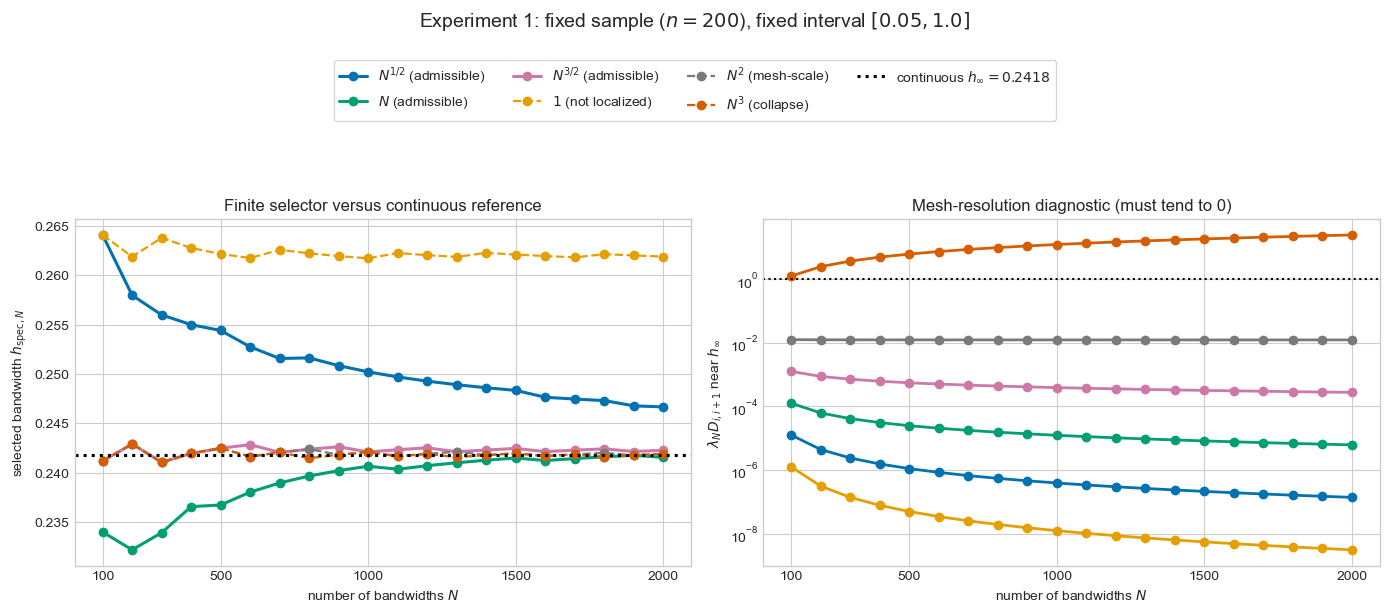

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))

for regime in REGIME_ORDER:
    subset = results[results["regime"] == regime]
    admissible = "admissible" in regime
    axes[0].plot(
        subset["N"], subset["selected_h"],
        marker="o",
        linewidth=2.2 if admissible else 1.6,
        linestyle="-" if admissible else "--",
        color=REGIME_COLORS[regime],
        label=regime,
    )
    axes[1].plot(
        subset["N"], subset["neighbor_exponent"],
        marker="o", linewidth=2.0,
        color=REGIME_COLORS[regime],
        label=regime,
    )

axes[0].axhline(
    h_infinity, color="black",
    linestyle=":", linewidth=2.2,
    label=rf"continuous $h_\infty={h_infinity:.4f}$",
)
axes[0].set(
    xlabel=r"number of bandwidths $N$",
    ylabel=r"selected bandwidth $h_{\mathrm{spec},N}$",
    title="Finite selector versus continuous reference",
)
axes[1].axhline(
    1.0, color="black", linestyle=":", linewidth=1.5
)
axes[1].set(
    yscale="log",
    xlabel=r"number of bandwidths $N$",
    ylabel=r"$\lambda_ND_{i,i+1}$ near $h_\infty$",
    title="Mesh-resolution diagnostic (must tend to 0)",
)
plot_ticks = np.array([100, 500, 1000, 1500, 2000])
for ax in axes:
    ax.set_xticks(plot_ticks, labels=plot_ticks)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.91), ncol=4, frameon=True
)
fig.suptitle(
    rf"Experiment 1: fixed sample ($n={N_DATA}$), "
    rf"fixed interval $[{H_MIN},{H_MAX}]$",
    y=0.98, fontsize=14,
)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.76))
plt.show()

,regime,lambda,lambda_over_N2,selected_h,absolute_error,global_exponent,neighbor_exponent,neighbor_similarity
19,$N^{1/2}$ (admissible),4.472136e+01,1.120000e-05,0.246669,0.004913,8.894765e-01,1.000000e-07,1.000000
39,$N$ (admissible),2.000000e+03,5.000000e-04,0.241548,0.000208,3.977860e+01,6.200000e-06,0.999994
59,$N^{3/2}$ (admissible),8.944272e+04,2.236070e-02,0.242273,0.000517,1.778953e+03,2.751000e-04,0.999725
79,$1$ (not localized),1.000000e+00,2.000000e-07,0.261908,0.020152,1.988930e-02,0.000000e+00,1.000000
99,$N^2$ (mesh-scale),4.000000e+06,1.000000e+00,0.241910,0.000154,7.955719e+04,1.230200e-02,0.987773
119,$N^3$ (collapse),8.000000e+09,2.000000e+03,0.241910,0.000154,1.591144e+08,2.460396e+01,0.000000


At N=2000, the admissible selectors span 0.005121 in bandwidth.


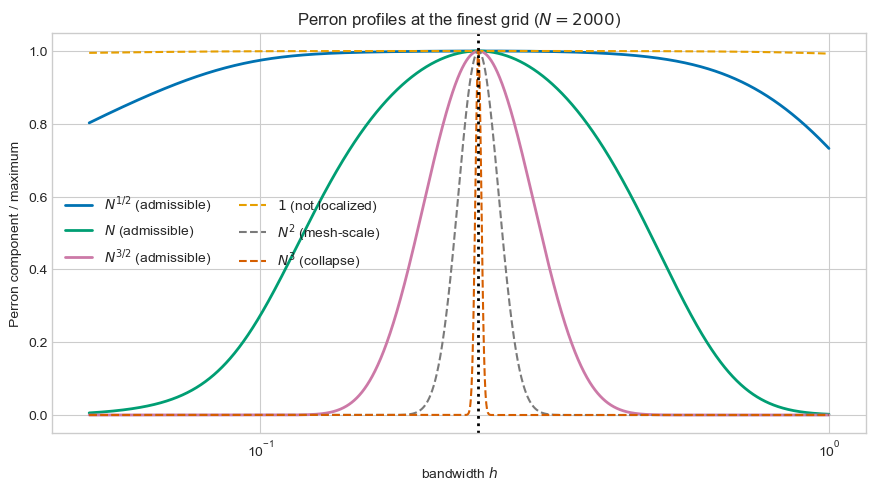

In [7]:
final_N = int(N_VALUES[-1])
final_diagnostics = results[
    results["N"] == final_N
][[
    "regime", "lambda", "lambda_over_N2",
    "selected_h", "absolute_error",
    "global_exponent", "neighbor_exponent",
    "neighbor_similarity",
]].copy()

admissible_final = final_diagnostics[
    final_diagnostics["regime"].isin(REGIME_ORDER[:3])
]
admissible_spread = (
    admissible_final["selected_h"].max()
    - admissible_final["selected_h"].min()
)
display(final_diagnostics.round(7))
print(
    f"At N={final_N}, the admissible selectors span "
    f"{admissible_spread:.6f} in bandwidth."
)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for regime in REGIME_ORDER:
    h_grid, vector = largest_grid_vectors[regime]
    admissible = "admissible" in regime
    ax.plot(
        h_grid, vector / vector.max(),
        color=REGIME_COLORS[regime],
        linewidth=2.0 if admissible else 1.5,
        linestyle="-" if admissible else "--",
        label=regime,
    )
ax.axvline(
    h_infinity, color="black",
    linestyle=":", linewidth=2.0
)
ax.set(
    xscale="log",
    xlabel=r"bandwidth $h$",
    ylabel="Perron component / maximum",
    title=rf"Perron profiles at the finest grid ($N={final_N}$)",
)
ax.legend(ncol=2)
plt.show()

## Dense exponent sweep: $\lambda_N=N^\alpha$

The six named regimes above are now replaced by a dense sweep

$$\alpha=0,0.2,0.4,\ldots,3.0,\qquad \lambda_N=N^\alpha.$$

The sample, bandwidth interval, $\psi_2$ parametrization, and values $N=100,200,\ldots,2000$ remain unchanged. The theoretical regions are:

- $\alpha=0$: $\lambda_N=1$ does not diverge;
- $0<\alpha<2$: $\lambda_N\to\infty$ and $\lambda_N/N^2\to0$;
- $\alpha=2$: mesh-scale boundary;
- $\alpha>2$: unresolved kernel regime.

Sixteen curves are shown together below. A heatmap of $h_{\mathrm{spec},N}-h_\infty$ provides a less cluttered view of the same results.

In [29]:
ALPHA_VALUES = np.round(
    np.arange(0.0, 3.0 + 0.1, 0.2),
    decimals=1,
)

alpha_rows = []
alpha_start_time = time.perf_counter()

for N in N_VALUES:
    N = int(N)
    h_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN,
        h_max=H_MAX,
        beta=BETA,
        grid_size=N,
    )
    divergence = beta2_divergence_matrix_fft(
        samples,
        h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )
    reference_index = nearest_bandwidth_grid_index(
        h_infinity, h_grid
    )
    neighbor_left = min(reference_index, N - 2)
    neighbor_divergence = divergence[
        neighbor_left, neighbor_left + 1
    ]

    for alpha in ALPHA_VALUES:
        lambda_value = float(N ** float(alpha))
        similarity = np.exp(
            -lambda_value * divergence
        )
        np.fill_diagonal(similarity, 1.0)
        vector = largest_symmetric_perron_vector(
            similarity
        )
        selected_index = int(np.argmax(vector))
        selected_h = float(h_grid[selected_index])

        alpha_rows.append({
            "N": N,
            "alpha": float(alpha),
            "lambda": lambda_value,
            "lambda_over_N2": lambda_value / N**2,
            "selected_index": selected_index,
            "selected_h": selected_h,
            "signed_error": selected_h - h_infinity,
            "absolute_error": abs(
                selected_h - h_infinity
            ),
            "neighbor_exponent": (
                lambda_value * neighbor_divergence
            ),
        })

alpha_results = pd.DataFrame(alpha_rows)
alpha_elapsed = time.perf_counter() - alpha_start_time
alpha_selected_pivot = alpha_results.pivot(
    index="N",
    columns="alpha",
    values="selected_h",
)

print(
    f"Completed {len(alpha_results)} alpha-sweep "
    f"selector runs in {alpha_elapsed:.2f} seconds."
)
display(alpha_selected_pivot.round(6))

Completed 320 alpha-sweep selector runs in 93.89 seconds.


alpha,0.0,0.2,0.4,0.6,0.8,1.0,1.2,1.4,1.6,1.8,2.0,2.2,2.4,2.6,2.8,3.0
N,,,,,,,,,,,,,,,,
100,0.264098,0.264098,0.264098,0.256226,0.248588,0.233990,0.233990,0.241179,0.241179,0.241179,0.241179,0.241179,0.241179,0.241179,0.241179,0.241179
200,0.261898,0.261898,0.261898,0.254130,0.242909,0.232183,0.239279,0.242909,0.242909,0.242909,0.242909,0.242909,0.242909,0.242909,0.242909,0.242909
300,0.263804,0.261174,0.258570,0.250914,0.238654,0.233919,0.241057,0.241057,0.241057,0.243484,0.241057,0.241057,0.241057,0.241057,0.241057,0.241057
400,0.262779,0.260813,0.258863,0.249325,0.236560,0.236560,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948
500,0.262167,0.260598,0.257487,0.246891,0.235313,0.236730,0.241033,0.242484,0.242484,0.242484,0.242484,0.242484,0.242484,0.242484,0.242484,0.242484
600,0.261760,0.261760,0.256575,0.246513,0.234487,0.238032,0.241630,0.242842,0.242842,0.241630,0.241630,0.241630,0.241630,0.241630,0.241630,0.241630
700,0.262593,0.261470,0.257026,0.245190,0.233899,0.238965,0.242058,0.242058,0.242058,0.242058,0.242058,0.242058,0.242058,0.242058,0.242058,0.242058
800,0.262234,0.261252,0.256400,0.244203,0.233459,0.239667,0.242378,0.242378,0.242378,0.242378,0.242378,0.241471,0.241471,0.241471,0.241471,0.241471
900,0.261955,0.261084,0.255915,0.243438,0.233896,0.240215,0.241821,0.242628,0.242628,0.241821,0.241821,0.241821,0.241821,0.241821,0.241821,0.241821


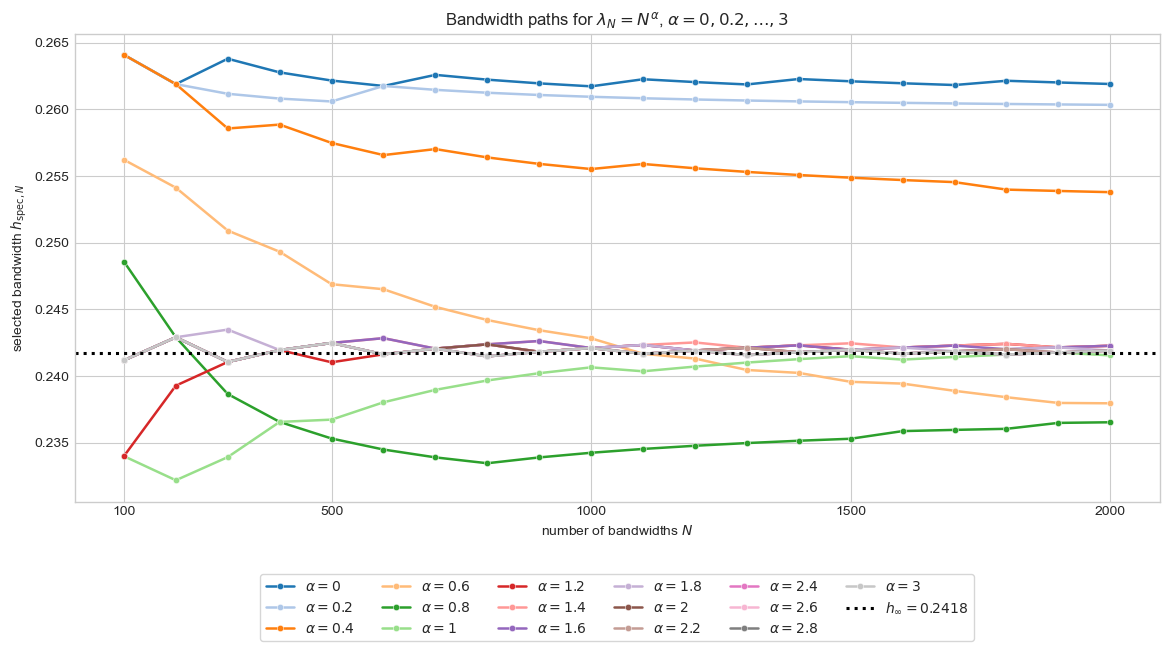

In [30]:
alpha_colors = plt.colormaps["tab20"](
    np.arange(len(ALPHA_VALUES))
)

fig, ax = plt.subplots(figsize=(14, 7.8))
for alpha_index, alpha in enumerate(ALPHA_VALUES):
    subset = alpha_results[
        alpha_results["alpha"] == alpha
    ]
    ax.plot(
        subset["N"],
        subset["selected_h"],
        color=alpha_colors[alpha_index],
        linewidth=1.8,
        marker="o",
        markersize=4.6,
        markeredgecolor="white",
        markeredgewidth=0.35,
        label=rf"$\alpha={alpha:g}$",
    )

ax.axhline(
    h_infinity,
    color="black",
    linestyle=":",
    linewidth=2.2,
    label=rf"$h_\infty={h_infinity:.4f}$",
)
ax.set(
    xlabel=r"number of bandwidths $N$",
    ylabel=r"selected bandwidth $h_{\mathrm{spec},N}$",
    title=(
        r"Bandwidth paths for $\lambda_N=N^\alpha$, "
        r"$\alpha=0,0.2,\ldots,3$"
    ),
)
ax.set_xticks([100, 500, 1000, 1500, 2000])
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=6,
    frameon=True,
)
fig.subplots_adjust(bottom=0.28)
plt.show()

In [28]:
alpha_final = alpha_results[
    alpha_results["N"] == int(N_VALUES[-1])
][[
    "alpha",
    "lambda_over_N2",
    "selected_h",
    "absolute_error",
    "neighbor_exponent",
]].copy()
alpha_final["theoretical_region"] = np.select(
    [
        alpha_final["alpha"] == 0.0,
        (
            (alpha_final["alpha"] > 0.0)
            & (alpha_final["alpha"] < 2.0)
        ),
        alpha_final["alpha"] == 2.0,
    ],
    [
        "not localized",
        "resolved joint limit",
        "mesh-scale boundary",
    ],
    default="unresolved",
)
display(alpha_final.round(7))

,alpha,lambda_over_N2,selected_h,absolute_error,neighbor_exponent,theoretical_region
304,0.0,2.000000e-07,0.261908,0.020152,0.000000e+00,not localized
305,0.2,1.100000e-06,0.260343,0.018586,0.000000e+00,resolved joint limit
306,0.4,5.200000e-06,0.253794,0.012038,1.000000e-07,resolved joint limit
307,0.6,2.390000e-05,0.237955,0.003801,3.000000e-07,resolved joint limit
308,0.8,1.093000e-04,0.236533,0.005223,1.300000e-06,resolved joint limit
309,1.0,5.000000e-04,0.241548,0.000208,6.200000e-06,resolved joint limit
310,1.2,2.286500e-03,0.242273,0.000517,2.810000e-05,resolved joint limit
311,1.4,1.045640e-02,0.242273,0.000517,1.286000e-04,resolved joint limit
312,1.6,4.781760e-02,0.242273,0.000517,5.883000e-04,resolved joint limit
313,1.8,2.186724e-01,0.241910,0.000154,2.690100e-03,resolved joint limit


### Reading the exponent sweep

The selected bandwidth alone need not separate the theoretical regions: exponents at and above two can still land near $h_\infty$ through the discrete nearest-neighbor mechanism. The heatmap should therefore be read together with the neighbor exponent and the Perron-profile diagnostics above. For the resolved continuous approximation, the relevant statement remains $0<\alpha<2$.

## Mesh-robustness stress test across all exponents

The same exponent grid as above is used:

$$\alpha=0,0.2,0.4,\ldots,3.0,\qquad \lambda_N=N^\alpha.$$

For each exponent, one point in an otherwise uniform $\psi_2=\log h$ grid is moved toward its left neighbor near $h=0.7$, far from the continuous prediction $h_\infty$. The endpoints, number of candidates, sample, bandwidth family, and all other grid points remain fixed.

The retained-gap fraction runs from one (the original uniform grid) down to $0.1$. A jump of the selected bandwidth toward $0.7$ indicates that the Perron vector has locked onto the artificial close pair.

**Scope.** This is a robustness stress test, not a counterexample under the theorem's exact uniform-grid assumptions.

In [33]:
MESH_STRESS_N = 400
MESH_TARGET_H = 0.70
MESH_ALPHA_VALUES = ALPHA_VALUES.copy()
MESH_ALPHA_COLORS = plt.colormaps["tab20"](
    np.arange(len(MESH_ALPHA_VALUES))
)
MESH_GAP_FRACTIONS = np.array([
    1.00, 0.90, 0.75, 0.60, 0.50, 0.40,
    0.35, 0.30, 0.25, 0.20, 0.15, 0.10,
])

mesh_base_grid = bandwidth_grid_linear_in_psi_beta(
    H_MIN,
    H_MAX,
    beta=BETA,
    grid_size=MESH_STRESS_N,
)
mesh_base_psi = np.log(mesh_base_grid)
mesh_delta_psi = (
    mesh_base_psi[1] - mesh_base_psi[0]
)
mesh_close_pair_left = int(
    np.argmin(
        np.abs(mesh_base_grid - MESH_TARGET_H)
    )
)
mesh_close_pair_left = min(
    mesh_close_pair_left,
    MESH_STRESS_N - 2,
)

mesh_rows = []
mesh_alpha3_profiles = {}

for gap_fraction in MESH_GAP_FRACTIONS:
    perturbed_psi = mesh_base_psi.copy()
    perturbed_psi[mesh_close_pair_left + 1] = (
        perturbed_psi[mesh_close_pair_left]
        + gap_fraction * mesh_delta_psi
    )
    h_grid = np.exp(perturbed_psi)
    divergence = beta2_divergence_matrix_fft(
        samples,
        h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )

    for alpha_index, alpha in enumerate(
        MESH_ALPHA_VALUES
    ):
        lambda_value = float(
            MESH_STRESS_N ** float(alpha)
        )
        similarity = np.exp(
            -lambda_value * divergence
        )
        np.fill_diagonal(similarity, 1.0)
        vector = largest_symmetric_perron_vector(
            similarity
        )
        selected_index = int(np.argmax(vector))

        mesh_rows.append({
            "gap_fraction": gap_fraction,
            "alpha": float(alpha),
            "lambda": lambda_value,
            "selected_h": float(
                h_grid[selected_index]
            ),
            "selected_index": selected_index,
            "close_pair_h_left": float(
                h_grid[mesh_close_pair_left]
            ),
            "close_pair_h_right": float(
                h_grid[mesh_close_pair_left + 1]
            ),
            "close_pair_similarity": float(
                similarity[
                    mesh_close_pair_left,
                    mesh_close_pair_left + 1,
                ]
            ),
        })

        if (
            np.isclose(alpha, 3.0)
            and gap_fraction in {1.0, 0.2}
        ):
            mesh_alpha3_profiles[gap_fraction] = (
                h_grid.copy(),
                vector.copy(),
            )

mesh_stress_results = pd.DataFrame(mesh_rows)
mesh_selected_table = mesh_stress_results.pivot(
    index="gap_fraction",
    columns="alpha",
    values="selected_h",
)
display(
    mesh_selected_table.loc[
        [1.0, 0.6, 0.4, 0.3, 0.2, 0.1]
    ].round(6)
)

alpha,0.0,0.2,0.4,0.6,0.8,1.0,1.2,1.4,1.6,1.8,2.0,2.2,2.4,2.6,2.8,3.0
gap_fraction,,,,,,,,,,,,,,,,
1.0,0.262779,0.260813,0.258863,0.249325,0.23656,0.23656,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948
0.6,0.262779,0.260813,0.258863,0.249325,0.23656,0.23656,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948
0.4,0.262779,0.260813,0.258863,0.249325,0.23656,0.23656,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948
0.3,0.262779,0.260813,0.258863,0.249325,0.23656,0.23656,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.697405
0.2,0.262779,0.260813,0.258863,0.249325,0.23656,0.23656,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.697405,0.698453
0.1,0.262779,0.260813,0.258863,0.249325,0.23656,0.23656,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.241948,0.697405,0.697929


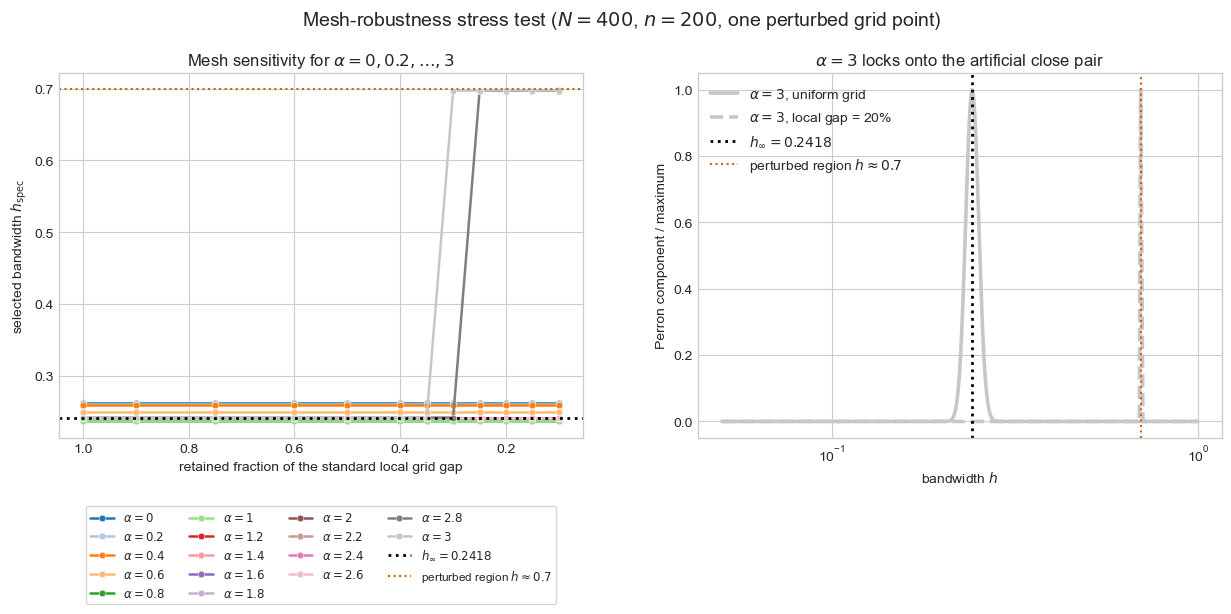

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))

for alpha_index, alpha in enumerate(
    MESH_ALPHA_VALUES
):
    subset = mesh_stress_results[
        mesh_stress_results["alpha"] == alpha
    ].sort_values(
        "gap_fraction",
        ascending=False,
    )
    axes[0].plot(
        subset["gap_fraction"],
        subset["selected_h"],
        color=MESH_ALPHA_COLORS[alpha_index],
        linewidth=1.8,
        marker="o",
        markersize=4.8,
        markeredgecolor="white",
        markeredgewidth=0.35,
        label=rf"$\alpha={alpha:g}$",
    )

axes[0].axhline(
    h_infinity,
    color="black",
    linestyle=":",
    linewidth=2.0,
    label=rf"$h_\infty={h_infinity:.4f}$",
)
axes[0].axhline(
    MESH_TARGET_H,
    color="#D55E00",
    linestyle=":",
    linewidth=1.5,
    label=(
        rf"perturbed region "
        rf"$h\approx{MESH_TARGET_H}$"
    ),
)
axes[0].invert_xaxis()
axes[0].set(
    xlabel=(
        "retained fraction of the standard "
        "local grid gap"
    ),
    ylabel=r"selected bandwidth $h_{\mathrm{spec}}$",
    title=(
        "Mesh sensitivity for "
        r"$\alpha=0,0.2,\ldots,3$"
    ),
)
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=4,
    fontsize=8.5,
    frameon=True,
)

alpha3_color = MESH_ALPHA_COLORS[-1]
for gap_fraction, linestyle in [
    (1.0, "-"),
    (0.2, "--"),
]:
    h_grid, vector = mesh_alpha3_profiles[
        gap_fraction
    ]
    axes[1].plot(
        h_grid,
        vector / vector.max(),
        color=alpha3_color,
        linestyle=linestyle,
        linewidth=2.6,
        label=(
            r"$\alpha=3$, uniform grid"
            if gap_fraction == 1.0
            else r"$\alpha=3$, local gap = 20%"
        ),
    )
axes[1].axvline(
    h_infinity,
    color="black",
    linestyle=":",
    linewidth=2.0,
    label=rf"$h_\infty={h_infinity:.4f}$",
)
axes[1].axvline(
    MESH_TARGET_H,
    color="#D55E00",
    linestyle=":",
    linewidth=1.5,
    label=(
        rf"perturbed region "
        rf"$h\approx{MESH_TARGET_H}$"
    ),
)
axes[1].set(
    xscale="log",
    xlabel=r"bandwidth $h$",
    ylabel="Perron component / maximum",
    title=(
        r"$\alpha=3$ locks onto "
        "the artificial close pair"
    ),
)
axes[1].legend()

fig.suptitle(
    rf"Mesh-robustness stress test "
    rf"($N={MESH_STRESS_N}$, "
    rf"$n={N_DATA}$, one perturbed grid point)",
    fontsize=14,
)
fig.subplots_adjust(bottom=0.31, wspace=0.22)
plt.show()

### Reading the mesh-robustness sweep

Each colored path uses the same α-color as the preceding bandwidth-path experiment. A horizontal path indicates that the selected bandwidth is insensitive to the isolated close pair. A jump toward $h\approx0.7$ indicates mesh locking.

The theoretical expectation is that exponents below two are increasingly well resolved as $N$ grows, whereas exponents above two become increasingly dependent on individual neighboring grid points. The exact perturbation level at which a path jumps is a finite-$N$ robustness diagnostic, not a new asymptotic boundary.

This experiment remains outside the perfectly uniform-grid assumption. Its purpose is to distinguish a resolved continuous-kernel selection from a fragile nearest-neighbor selection when both happen to return approximately $h_\infty$ on the ideal grid.

## Interpretation

- The three admissible sequences approach the same sample-conditional continuous reference, although $N^{1/2}$ localizes more slowly than $N$ and $N^{3/2}$.
- With $\lambda_N=1$, the kernel never becomes globally localized. Its selector can stabilize, but not at the large-$\lambda$ criterion.
- With $\lambda_N=N^2$, the neighbor exponent remains at mesh scale instead of tending to zero. The selected bandwidth may look plausible, but it is a discretized-kernel limit rather than the target continuous local limit.
- With $\lambda_N=N^3$, neighboring similarities collapse toward zero and the matrix approaches the identity. The Perron eigenvalue becomes nearly degenerate, so an apparently accurate argmax is not evidence of the desired limit.

This is why the mesh diagnostic and final table are part of Experiment 1: the bandwidth path alone cannot verify the joint-limit assumptions.

## Scope and reproducibility

Change SEED or N_DATA only for a robustness rerun; keep them fixed within a run. The experiment intentionally makes no comparison with $h_{\mathrm{AMISE}}$ and no claim about $n\to\infty$. Those belong to Experiment 2.